# Thesis Figures: Online Recruitment Fraud Detection (DistilRoBERTa + GraphSAGE)

This notebook regenerates every chart and diagram for Chapters III and IV, with a short explanation of what each one shows and how to read it. Change numbers or colors in the **Config** and **Data** cells, then re-run.

**How to use**
1. Run the Config cell, then the Data cell. The Data cell holds the numbers from the Chapter IV draft.
2. To use your real result files instead, set `USE_JSON = True` in Config and point the paths at `cv_results_random_seed42.json`, `cv_results_group_seed42.json` and the two `complementarity_report_*.json` files.
3. Run any figure cell. PNGs are saved to `OUT_DIR`.

**Figures (numbering follows the chapters)**
- 3.1 Pipeline overview, 3.2 Fusion architectures, 4.1 System architecture (diagrams)
- 4.7 Per-fold F1 dot plot, 4.8 Random vs group dumbbell, 4.9 Connectivity, 4.10 Complementarity, 4.11/4.12 Occlusion explanations, 4.13 Forest plot

Screenshots (Figures 4.2 to 4.6) are not generated here.

## Config
Everything you are likely to tweak lives here.

In [1]:
import json, os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

OUT_DIR = "figs"          # where PNGs are saved
DPI = 200                 # 200 is fine for Word/Docs; use 300 for print
SHOW = True               # show figures in the notebook as well as saving

# Set True to read the real result files instead of the numbers typed in the Data cell
USE_JSON = False
JSON_PATHS = {
    "random": "outputs/cv_results_random_seed42.json",
    "group":  "outputs/cv_results_group_seed42.json",
    "comp_random": "outputs/complementarity_report_random.json",
    "comp_group":  "outputs/complementarity_report_group.json",
}

# Display names and colors, in plotting order
CONDITIONS = ["distilroberta_only", "text_tabular", "graphsage_only", "late_concat", "cross_attention"]
NAMES = {"distilroberta_only":"DistilRoBERTa-only","text_tabular":"Text + Tabular","graphsage_only":"GraphSAGE-only",
         "late_concat":"Hybrid, late concat","cross_attention":"Hybrid, cross-attention"}
COLORS = {"distilroberta_only":"#7B8794","text_tabular":"#A9B4C0","graphsage_only":"#C98B5B","late_concat":"#2F6F9F","cross_attention":"#1B9C85"}
C_RANDOM, C_GROUP = "#2F6F9F", "#C0504D"     # random-split vs group-split colors used across charts

plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11,"axes.spines.top":False,"axes.spines.right":False})
os.makedirs(OUT_DIR, exist_ok=True)

def save(fig, name):
    path = os.path.join(OUT_DIR, name)
    fig.savefig(path, dpi=DPI, bbox_inches="tight", facecolor="white")
    if SHOW: plt.show()
    plt.close(fig)
    print("saved", path)

def box(ax,x,y,w,h,t,fc="#EAF1F7",ec="#2F6F9F",fs=10):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle="round,pad=0.02,rounding_size=0.08",fc=fc,ec=ec,lw=1.4))
    ax.text(x+w/2,y+h/2,t,ha="center",va="center",fontsize=fs)

def arrow(ax,x1,y1,x2,y2):
    ax.add_patch(FancyArrowPatch((x1,y1),(x2,y2),arrowstyle="-|>",mutation_scale=14,lw=1.4,color="#444"))

## Data
Numbers from the Chapter IV draft (tables IV.4, IV.6, IV.9, IV.10, IV.11, IV.12 and the occlusion values in Section E.6). Each per-fold list has 5 values, one per fold.

**Warning:** your Oct 31 result files give slightly different numbers than the draft (for example GraphSAGE-only random F1 0.539 vs 0.522). Decide which run is final, then either edit these lists or switch on `USE_JSON`.

In [3]:
# Per-fold F1 (rows: conditions in CONDITIONS order). Source: Tables IV.4 and IV.6
F1 = {
 "random": {
  "distilroberta_only":[.4875,.5200,.4814,.5203,.5418],
  "text_tabular":      [.5464,.5354,.5488,.4148,.5789],
  "graphsage_only":    [.4779,.4656,.5357,.5328,.5978],
  "late_concat":       [.7826,.7827,.7403,.7481,.7990],
  "cross_attention":   [.7422,.7174,.7160,.7565,.7784]},
 "group": {
  "distilroberta_only":[.2633,.2563,.2618,.2311,.2301],
  "text_tabular":      [.3077,.2986,.3996,.3081,.3719],
  "graphsage_only":    [.2086,.2025,.2277,.2739,.2018],
  "late_concat":       [.3907,.4468,.4043,.6642,.4983],
  "cross_attention":   [.3713,.6383,.3648,.6461,.5298]},
}

# Connectivity (cross-attention). Source: Table IV.9. fa_rate = false alarms / legitimate, in %
CONN = {
 "random": {"connected":{"scams":369,"caught":306,"fa_rate":0.35}, "isolated":{"scams":336,"caught":175,"fa_rate":3.40}},
 "group":  {"connected":{"scams":369,"caught":178,"fa_rate":2.11}, "isolated":{"scams":336,"caught":182,"fa_rate":5.05}},
}

# Complementarity: scams detected by standalone models (of 705). Source: Table IV.10
COMP = {"random":{"neither":160,"text_only":160,"graph_only":198,"both":187},
        "group": {"neither":203,"text_only":47,"graph_only":266,"both":189}}

# Occlusion: score with the field minus score without it. Source: Section E.6.
# Benefits is missing in the draft; add it when you have the value from the screenshot.
OCC = {
 "Case 1: Data Entry Assistant (SCAM, score 0.4268)": {"Title":-0.002,"Company profile":-0.187,"Description":0.018,"Requirements":-0.072},
 "Case 2: Senior Software Engineer (LEGIT, score 0.124)": {"Title":-0.001,"Company profile":0.003,"Description":-0.043,"Requirements":-0.013},
}

# Paired tests: (label, mean diff, CI low, CI high) for cross-attention minus comparison. Source: Tables IV.11 and IV.12
FOREST = {
 "random": [("H1 vs DistilRoBERTa, F1",.2319,.2058,.2579),("H1 vs DistilRoBERTa, MCC",.2419,.2111,.2727),
            ("H2 vs GraphSAGE, F1",.2201,.1715,.2687),("H2 vs GraphSAGE, MCC",.2050,.1494,.2605),
            ("H3 vs late fusion, F1",-.0285,-.0621,.0052),("H3 vs late fusion, MCC",-.0317,-.0628,-.0005)],
 "group":  [("H1 vs DistilRoBERTa, F1",.2615,.0771,.4460),("H1 vs DistilRoBERTa, MCC",.2732,.0751,.4713),
            ("H2 vs GraphSAGE, F1",.2872,.1241,.4502),("H2 vs GraphSAGE, MCC",.2788,.1104,.4472),
            ("H3 vs late fusion, F1",.0292,-.0880,.1465),("H3 vs late fusion, MCC",.0268,-.0891,.1426)],
}

### Optional: load from your real JSON files
When `USE_JSON = True`, this cell overwrites the per-fold F1, connectivity and complementarity data from your result files. The occlusion values stay manual because they come from the web demo. The forest plot is recomputed from per-fold F1 and MCC (paired differences, 95% t-interval), so it will not exactly match `stats_test.py`, which also reports corrected tests. Keep the table values in `FOREST` if you want the exact printed numbers.

In [4]:
def load_results(path):
    with open(path) as f: return json.load(f)

if USE_JSON:
    from scipy import stats
    new_forest = {}
    for split in ("random","group"):
        r = load_results(JSON_PATHS[split])["results"]
        F1[split] = {c:[fold["f1"] for fold in r[c]] for c in CONDITIONS}
        # connectivity pooled over folds
        cn = {}
        for part in ("connected","isolated"):
            scams = sum(x[part]["n_scams"] for x in r["connectivity"])
            caught = sum(x[part]["scams_caught"] for x in r["connectivity"])
            fa = sum(x[part]["false_alarms"] for x in r["connectivity"])
            legit = sum(x[part]["n_legit"] for x in r["connectivity"])
            cn[part] = {"scams":scams,"caught":caught,"fa_rate":100*fa/legit}
        CONN[split] = cn
        c = load_results(JSON_PATHS["comp_"+split])  # report with pooled counts is nested differently in some versions
        pooled = c.get("pooled", c)
        COMP[split] = {k:pooled[k] for k in ("neither","text_only","graph_only","both")}
        # forest from paired differences
        rows=[]
        for lab,base in (("H1 vs DistilRoBERTa","distilroberta_only"),("H2 vs GraphSAGE","graphsage_only"),("H3 vs late fusion","late_concat")):
            for met in ("f1","mcc"):
                d = np.array([a[met]-b[met] for a,b in zip(r["cross_attention"], r[base])])
                m, se = d.mean(), d.std(ddof=1)/np.sqrt(len(d)); t = stats.t.ppf(.975, len(d)-1)
                rows.append((f"{lab}, {met.upper()}", m, m-t*se, m+t*se))
        new_forest[split] = rows
    FOREST = new_forest
    print("Loaded from JSON.")
else:
    print("Using the numbers typed in the Data cell.")

Using the numbers typed in the Data cell.


## Figure 3.1: Pipeline overview
**What it shows:** the eight steps from raw EMSCAD data to test metrics. **How to read it:** left to right. Two points matter for the defense: embeddings are computed once and cached, and the test fold is never used for early stopping or threshold selection. Edit the `stages` list to rename or reorder boxes.

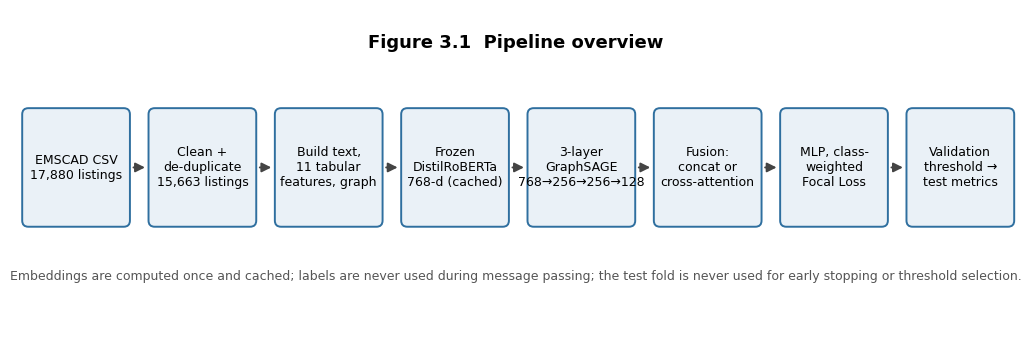

saved figs\fig_3_1_pipeline_overview.png


In [5]:
stages = ["EMSCAD CSV\n17,880 listings","Clean +\nde-duplicate\n15,663 listings","Build text,\n11 tabular\nfeatures, graph","Frozen\nDistilRoBERTa\n768-d (cached)",
          "3-layer\nGraphSAGE\n768→256→256→128","Fusion:\nconcat or\ncross-attention","MLP, class-\nweighted\nFocal Loss","Validation\nthreshold →\ntest metrics"]
fig, ax = plt.subplots(figsize=(13,4.2)); ax.axis("off"); ax.set_xlim(0,13); ax.set_ylim(0,4.2)
w, g = 1.35, 0.28
for i,t in enumerate(stages):
    x = 0.15 + i*(w+g); box(ax,x,1.4,w,1.5,t,fs=9)
    if i < len(stages)-1: arrow(ax,x+w+0.03,2.15,x+w+g-0.03,2.15)
ax.text(6.5,3.7,"Figure 3.1  Pipeline overview",ha="center",fontsize=13,weight="bold")
ax.text(6.5,0.7,"Embeddings are computed once and cached; labels are never used during message passing; the test fold is never used for early stopping or threshold selection.",ha="center",fontsize=9,color="#555")
save(fig,"fig_3_1_pipeline_overview.png")

## Figure 3.2: Fusion architectures
**What it shows:** the two hybrids side by side. Late concatenation just joins [text; final graph hop; tabular] (907-d). Cross-attention projects the text and the three GraphSAGE hops into a shared space, lets the text attend over the hops, pools the hops with a learned query, and concatenates everything (1,163-d). **Why it matters:** this is the single difference Hypothesis 3 tests, so keep the diagram faithful to the code if you change the model.

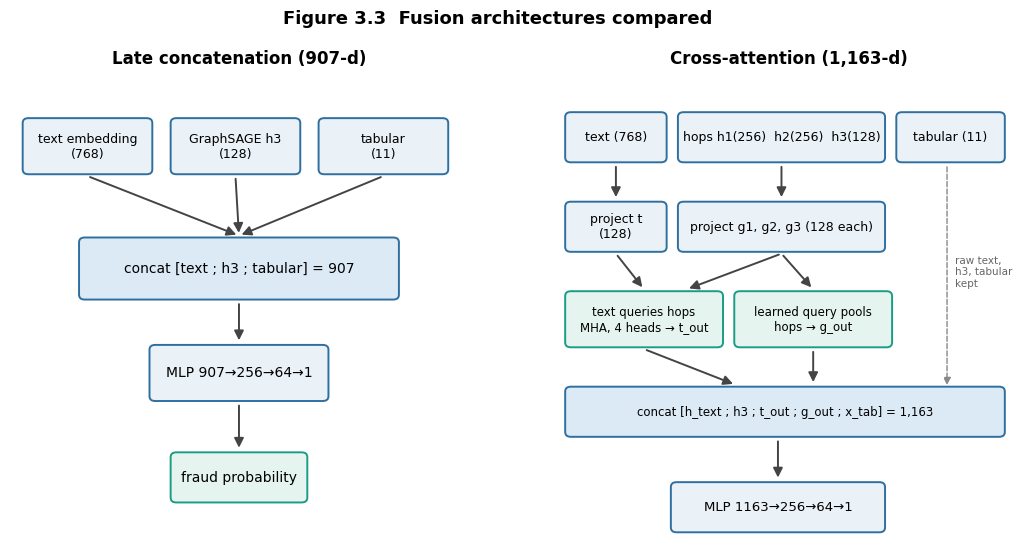

saved figs\fig_3_2_fusion_architectures.png


In [14]:
fig, axs = plt.subplots(1,2,figsize=(13,6.2))
for a in axs: a.axis("off"); a.set_xlim(0,6.5); a.set_ylim(0,8)
a = axs[0]; a.set_title("Late concatenation (907-d)",fontsize=12,weight="bold")
box(a,0.2,6.3,1.8,0.9,"text embedding\n(768)",fs=9); box(a,2.3,6.3,1.8,0.9,"GraphSAGE h3\n(128)",fs=9); box(a,4.4,6.3,1.8,0.9,"tabular\n(11)",fs=9)
box(a,1.0,4.2,4.5,1.0,"concat [text ; h3 ; tabular] = 907",fc="#DCEAF5")
for x in (1.1,3.2,5.3): arrow(a,x,6.25,3.25,5.25)
box(a,2.0,2.5,2.5,0.9,"MLP 907→256→64→1"); arrow(a,3.25,4.15,3.25,3.45)
box(a,2.3,0.8,1.9,0.8,"fraud probability",fc="#E6F4EF",ec="#1B9C85"); arrow(a,3.25,2.45,3.25,1.65)
a = axs[1]; a.set_title("Cross-attention (1,163-d)",fontsize=12,weight="bold")
box(a,0.1,6.5,1.4,0.8,"text (768)",fs=9); box(a,1.7,6.5,2.9,0.8,"hops h1(256)  h2(256)  h3(128)",fs=9); box(a,4.8,6.5,1.5,0.8,"tabular (11)",fs=9)
box(a,0.1,5.0,1.4,0.8,"project t\n(128)",fs=9); box(a,1.7,5.0,2.9,0.8,"project g1, g2, g3 (128 each)",fs=9)
arrow(a,0.8,6.45,0.8,5.85); arrow(a,3.15,6.45,3.15,5.85)
box(a,0.1,3.4,2.2,0.9,"text queries hops\nMHA, 4 heads → t_out",fc="#E6F4EF",ec="#1B9C85",fs=8.5)
box(a,2.5,3.4,2.2,0.9,"learned query pools\nhops → g_out",fc="#E6F4EF",ec="#1B9C85",fs=8.5)
arrow(a,0.8,4.95,1.2,4.35); arrow(a,3.15,4.95,1.8,4.35); arrow(a,3.15,4.95,3.6,4.35)
box(a,0.1,1.9,6.2,0.8,"concat [h_text ; h3 ; t_out ; g_out ; x_tab] = 1,163",fc="#DCEAF5",fs=8.5)
arrow(a,1.2,3.35,2.5,2.75); arrow(a,3.6,3.35,3.6,2.75)
a.annotate("",xy=(5.5,2.7),xytext=(5.5,6.45),arrowprops=dict(arrowstyle="-|>",color="#888",ls="--"))
a.text(5.62,4.4,"raw text,\nh3, tabular\nkept",fontsize=7.5,color="#666",ha="left")
box(a,1.6,0.3,3.0,0.8,"MLP 1163→256→64→1",fs=9.5); arrow(a,3.1,1.85,3.1,1.15)
fig.suptitle("Figure 3.3  Fusion architectures compared",fontsize=13,weight="bold",y=0.98)
save(fig,"fig_3_2_fusion_architectures.png")

## Figure 4.1: System architecture
**What it shows:** the software, not the method. Top row is data and model preparation; bottom row is the evaluation scripts. **Use:** put it in Section A of Chapter IV. Rename boxes if your file names change.

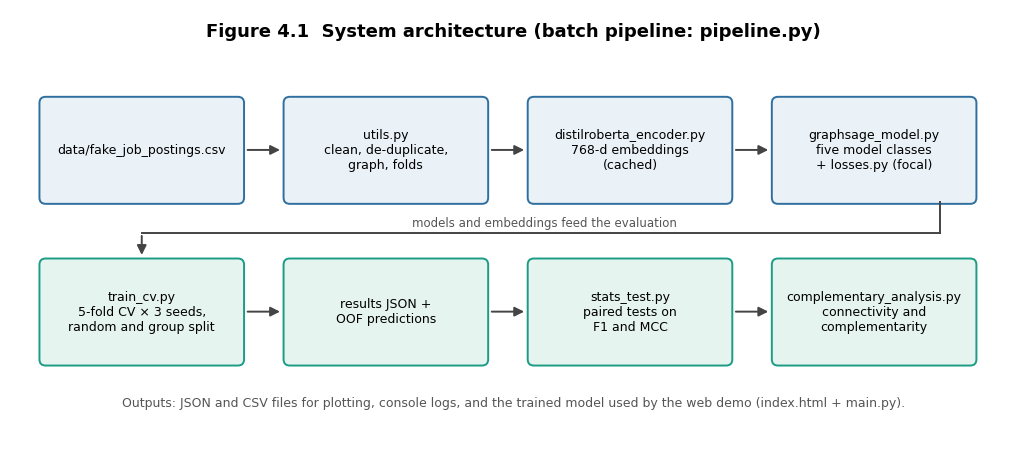

saved figs\fig_4_1_system_architecture.png


In [7]:
rows = [("data/fake_job_postings.csv","utils.py\nclean, de-duplicate,\ngraph, folds","distilroberta_encoder.py\n768-d embeddings\n(cached)","graphsage_model.py\nfive model classes\n+ losses.py (focal)"),
        ("train_cv.py\n5-fold CV × 3 seeds,\nrandom and group split","results JSON +\nOOF predictions","stats_test.py\npaired tests on\nF1 and MCC","complementary_analysis.py\nconnectivity and\ncomplementarity")]
fig, ax = plt.subplots(figsize=(13,5.6)); ax.axis("off"); ax.set_xlim(0,13); ax.set_ylim(0,5.6)
ax.text(6.5,5.25,"Figure 4.1  System architecture (batch pipeline: pipeline.py)",ha="center",fontsize=13,weight="bold")
for r,row in enumerate(rows):
    y = 3.1 if r==0 else 1.0
    for i,t in enumerate(row):
        x = 0.4 + i*3.15
        box(ax,x,y,2.6,1.35,t,fs=9,fc="#EAF1F7" if r==0 else "#E6F4EF",ec="#2F6F9F" if r==0 else "#1B9C85")
        if i<3: arrow(ax,x+2.63,y+0.68,x+3.12,y+0.68)
ax.plot([12.0,12.0],[3.1,2.7],color="#444",lw=1.4); ax.plot([12.0,1.7],[2.7,2.7],color="#444",lw=1.4); arrow(ax,1.7,2.7,1.7,2.38)
ax.text(6.9,2.78,"models and embeddings feed the evaluation",ha="center",fontsize=8.5,color="#555")
ax.text(6.5,0.45,"Outputs: JSON and CSV files for plotting, console logs, and the trained model used by the web demo (index.html + main.py).",ha="center",fontsize=9,color="#555")
save(fig,"fig_4_1_system_architecture.png")

## Figure 4.7: Per-fold F1 (dot plot)
**What it shows:** every fold's F1 as a dot, with the mean as a black bar, for each model, under the random split (left) and group split (right). **How to read it:** the two hybrids sit far to the right of the single-source models in both panels. In the group panel the hybrids' dots spread widely (about 0.36 to 0.66), which is why the fusion comparison is inconclusive. Fold-to-fold spread is as important as the mean here.

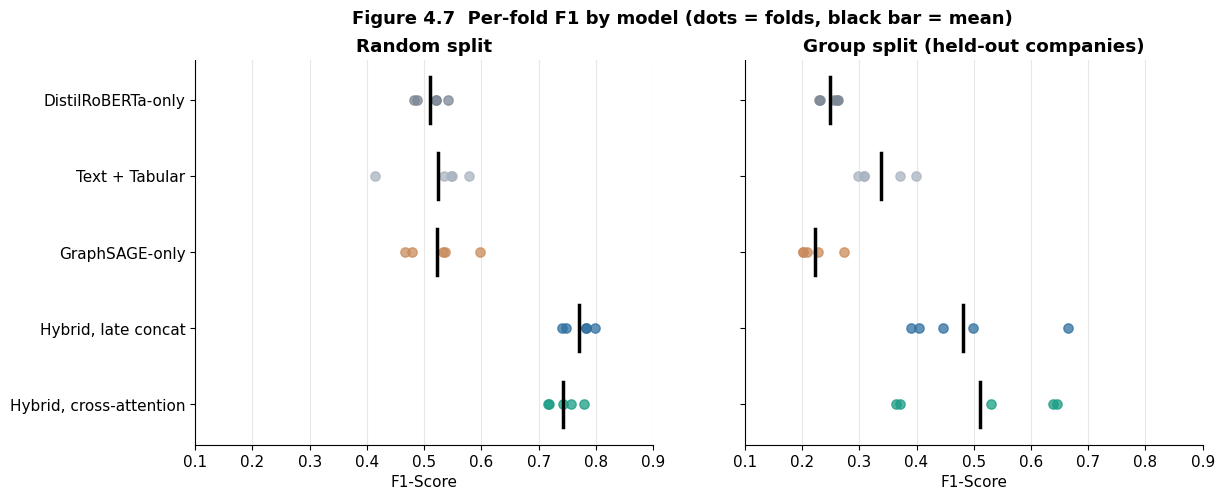

saved figs\fig_4_7_perfold_f1_dotplot.png


In [8]:
fig, axs = plt.subplots(1,2,figsize=(13,5),sharey=True)
for a,split,title in zip(axs,("random","group"),("Random split","Group split (held-out companies)")):
    for i,c in enumerate(CONDITIONS):
        v = F1[split][c]; y = len(CONDITIONS)-1-i
        a.scatter(v,[y]*len(v),color=COLORS[c],s=45,alpha=.75,zorder=3)
        a.plot([np.mean(v)]*2,[y-.3,y+.3],color="black",lw=2.5,zorder=4)
    a.set_yticks(range(len(CONDITIONS))); a.set_yticklabels([NAMES[c] for c in CONDITIONS][::-1])
    a.set_xlabel("F1-Score"); a.set_title(title,weight="bold"); a.grid(axis="x",alpha=.3); a.set_xlim(0.1,0.9)
fig.suptitle("Figure 4.7  Per-fold F1 by model (dots = folds, black bar = mean)",fontsize=13,weight="bold")
save(fig,"fig_4_7_perfold_f1_dotplot.png")

## Figure 4.8: Random vs group F1 (dumbbell)
**What it shows:** each model's mean F1 under the random split (blue) and group split (red), joined by a line, with the change printed on the right. **How to read it:** a longer line means the model leaned more on having seen related listings. Every model drops. GraphSAGE-only drops most (it has no text to fall back on), and cross-attention drops least, but fold spread under the group split is too large to claim that difference is real.

Text(0.5, 1.0, 'Figure 4.8  F1 drops when whole companies are held out')

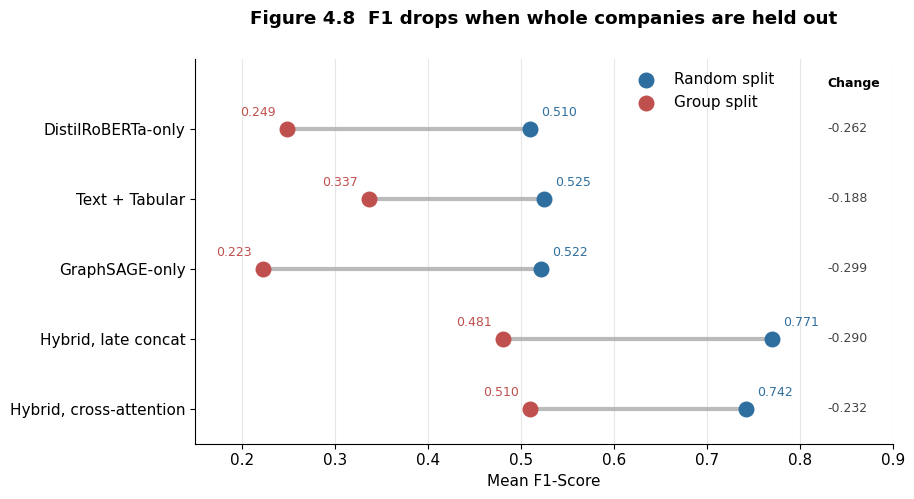

In [18]:
mr = {c:np.mean(F1["random"][c]) for c in CONDITIONS}; mg = {c:np.mean(F1["group"][c]) for c in CONDITIONS}
fig, ax = plt.subplots(figsize=(9,5))
for i,c in enumerate(CONDITIONS):
    y = len(CONDITIONS)-1-i
    ax.plot([mg[c],mr[c]],[y,y],color="#bbb",lw=3,zorder=1)
    ax.scatter(mr[c],y,color=C_RANDOM,s=110,zorder=3,label="Random split" if i==0 else None)
    ax.scatter(mg[c],y,color=C_GROUP,s=110,zorder=3,label="Group split" if i==0 else None)
    ax.text(mr[c]+.012,y+.18,f"{mr[c]:.3f}",fontsize=9,color=C_RANDOM)
    ax.text(mg[c]-.012,y+.18,f"{mg[c]:.3f}",fontsize=9,color=C_GROUP,ha="right")
    ax.text(0.83,y,f"{mg[c]-mr[c]:+.3f}",fontsize=9,va="center",color="#444")
ax.text(0.83,len(CONDITIONS)-0.4,"Change",fontsize=9,weight="bold")
ax.set_yticks(range(len(CONDITIONS))); ax.set_yticklabels([NAMES[c] for c in CONDITIONS][::-1])
ax.set_ylim(-0.5, len(CONDITIONS)); ax.set_xlim(.15,.9); ax.set_xlabel("Mean F1-Score"); ax.grid(axis="x",alpha=.3); ax.legend(loc="upper right", bbox_to_anchor=(0.85, 1), frameon=False)
ax.set_title("Figure 4.8  F1 drops when whole companies are held out", weight="bold", pad=25)

## Figure 4.9: Connected vs isolated listings
**What it shows:** the cross-attention model's recall (left) and false-alarm rate (right) for test listings that have at least one graph neighbor versus listings with none. **How to read it:** under the random split, connected scams are caught well (0.83) because their neighbors are in training. Under the group split, connected recall collapses (0.48) while isolated recall barely moves (0.52 to 0.54). That gap is the direct evidence that the random-split advantage came from related listings being visible in training.

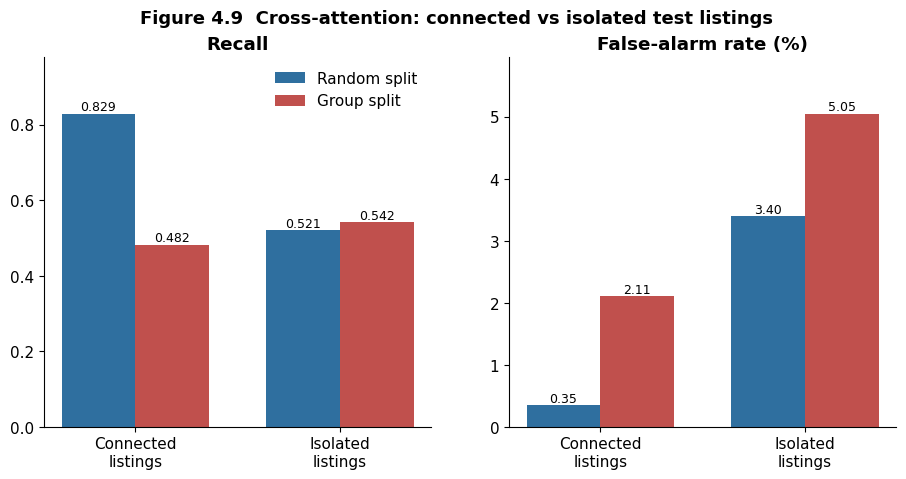

saved figs\fig_4_9_connectivity.png


In [10]:
def conn_metrics(split, part):
    d = CONN[split][part]; return d["caught"]/d["scams"], d["fa_rate"]
vals = {s:{p:conn_metrics(s,p) for p in ("connected","isolated")} for s in ("random","group")}
fig, axs = plt.subplots(1,2,figsize=(11,4.8)); x = np.arange(2); w = .36
for a,k,ttl,fmt in zip(axs,(0,1),("Recall","False-alarm rate (%)"),("{:.3f}","{:.2f}")):
    r = [vals["random"][p][k] for p in ("connected","isolated")]; g = [vals["group"][p][k] for p in ("connected","isolated")]
    b1 = a.bar(x-w/2,r,w,color=C_RANDOM,label="Random split"); b2 = a.bar(x+w/2,g,w,color=C_GROUP,label="Group split")
    for b in list(b1)+list(b2): a.text(b.get_x()+b.get_width()/2,b.get_height(),fmt.format(b.get_height()),ha="center",va="bottom",fontsize=9)
    a.set_xticks(x); a.set_xticklabels(["Connected\nlistings","Isolated\nlistings"]); a.set_title(ttl,weight="bold"); a.set_ylim(0,max(r+g)*1.18)
axs[0].legend(frameon=False)
fig.suptitle("Figure 4.9  Cross-attention: connected vs isolated test listings",fontsize=13,weight="bold")
save(fig,"fig_4_9_connectivity.png")

## Figure 4.10: Complementarity
**What it shows:** of the 705 fraudulent listings, how many were caught by neither standalone model, only text, only graph, or both. **How to read it:** a large "text only" and "graph only" segment means the models catch different scams, which is why combining them helps. The grey "neither" segment (about a quarter of scams) is the ceiling the hybrids have to work against; they recover roughly one in five of those. Note how the group split shifts weight from "text only" to "graph only".

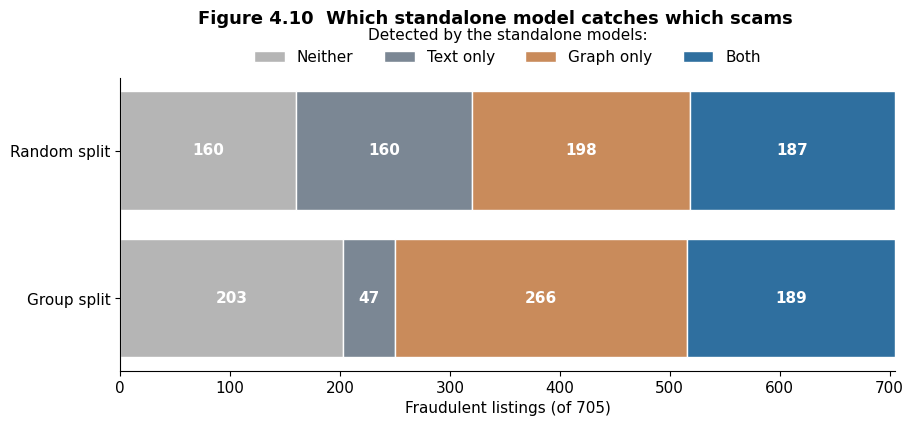

saved figs\fig_4_10_complementarity.png


In [11]:
cats = ["neither","text_only","graph_only","both"]; labels = ["Neither","Text only","Graph only","Both"]
cc = ["#B5B5B5","#7B8794","#C98B5B","#2F6F9F"]
fig, ax = plt.subplots(figsize=(10,3.8))
for y,(lab,split) in enumerate((("Group split","group"),("Random split","random"))):
    left = 0
    for k,c,l in zip(cats,cc,labels):
        v = COMP[split][k]
        ax.barh(y,v,left=left,color=c,label=l if y==0 else None,edgecolor="white")
        ax.text(left+v/2,y,str(v),ha="center",va="center",color="white",fontsize=11,weight="bold"); left += v
ax.set_yticks([0,1]); ax.set_yticklabels(["Group split","Random split"]); ax.set_xlabel("Fraudulent listings (of 705)"); ax.set_xlim(0,705)
ax.legend(ncol=4,loc="upper center",bbox_to_anchor=(.5,1.22),frameon=False,title="Detected by the standalone models:")
fig.suptitle("Figure 4.10  Which standalone model catches which scams",fontsize=13,weight="bold",y=1.06)
save(fig,"fig_4_10_complementarity.png")

## Figures 4.11 and 4.12: Occlusion explanations
**What it shows:** for each demo case, how the model's score changes when one text field is removed. Positive (red) means the field pushed the score toward scam; negative (blue) toward legitimate. **How to read it:** in Case 1 the polished company profile pulls the score strongly toward legitimate (−0.187), which is what keeps a scam-style posting at the decision threshold. That supports the limitation that a frozen, generic encoder reads fluent corporate text as legitimate. These are two examples, not a measurement of explanation quality. Add `"Benefits"` to each case in the Data cell once you have the values.

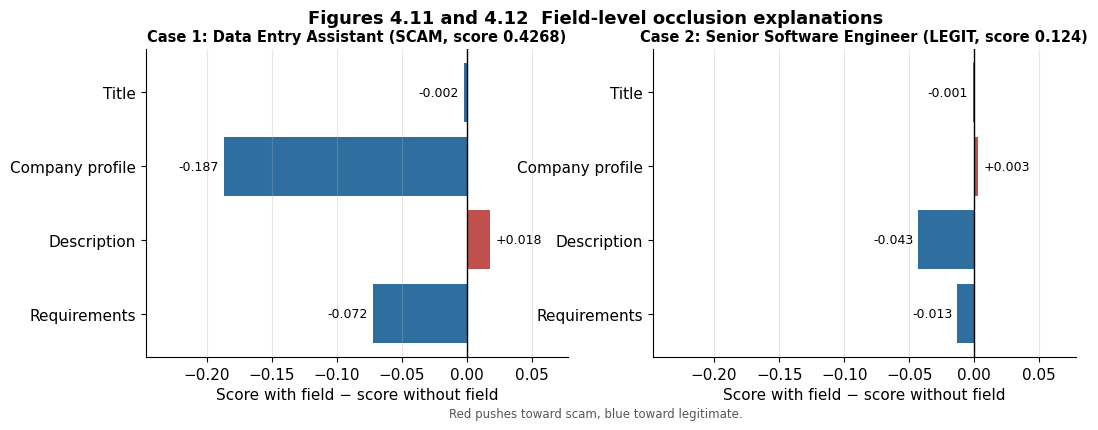

saved figs\fig_4_11_4_12_occlusion.png


In [12]:
fig, axs = plt.subplots(1,len(OCC),figsize=(6*len(OCC),4),sharex=True)
axs = np.atleast_1d(axs)
for a,(title,d) in zip(axs,OCC.items()):
    names = list(d.keys()); v = list(d.values())
    a.barh(names[::-1],v[::-1],color=[C_GROUP if x>0 else C_RANDOM for x in v[::-1]])
    a.axvline(0,color="black",lw=1); a.set_title(title,fontsize=10.5,weight="bold"); a.grid(axis="x",alpha=.3)
    for i,x in enumerate(v[::-1]): a.text(x+(0.004 if x>=0 else -0.004),i,f"{x:+.3f}",va="center",ha="left" if x>=0 else "right",fontsize=9)
    a.set_xlabel("Score with field − score without field")
lo = min(min(d.values()) for d in OCC.values()); hi = max(max(d.values()) for d in OCC.values())
axs[0].set_xlim(lo-0.06, hi+0.06)
fig.text(.5,-0.04,"Red pushes toward scam, blue toward legitimate.",ha="center",fontsize=8.5,color="#555")
fig.suptitle("Figures 4.11 and 4.12  Field-level occlusion explanations",fontsize=13,weight="bold")
save(fig,"fig_4_11_4_12_occlusion.png")

## Figure 4.13: Forest plot of paired differences
**What it shows:** the mean per-fold difference (cross-attention minus comparison model) with a 95% confidence interval, for H1, H2 and H3 on F1 and MCC, under both splits. **How to read it:** an interval that does not cross zero means a significant difference. H1 and H2 sit clearly right of zero. H3's intervals cross zero in both splits, so cross-attention is not shown to beat late concatenation. Note that group-split intervals are much wider, reflecting the large fold variance.

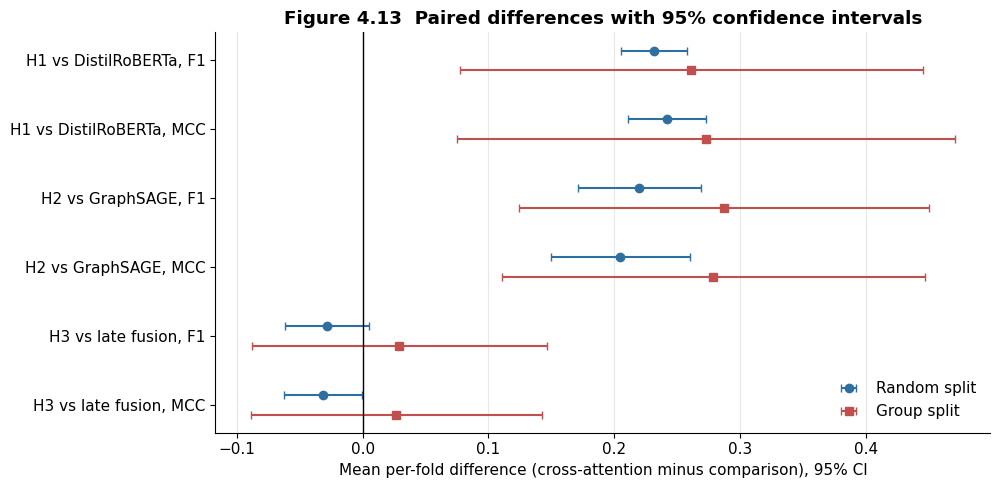

saved figs\fig_4_13_forest_plot.png


In [13]:
rows_r, rows_g = FOREST["random"], FOREST["group"]
fig, ax = plt.subplots(figsize=(10,5.2))
for i,(r,g) in enumerate(zip(rows_r,rows_g)):
    y = len(rows_r)-1-i
    ax.errorbar(r[1],y+.14,xerr=[[r[1]-r[2]],[r[3]-r[1]]],fmt="o",color=C_RANDOM,capsize=3,label="Random split" if i==0 else None)
    ax.errorbar(g[1],y-.14,xerr=[[g[1]-g[2]],[g[3]-g[1]]],fmt="s",color=C_GROUP,capsize=3,label="Group split" if i==0 else None)
ax.axvline(0,color="black",lw=1)
ax.set_yticks(range(len(rows_r))); ax.set_yticklabels([r[0] for r in rows_r][::-1])
ax.set_xlabel("Mean per-fold difference (cross-attention minus comparison), 95% CI"); ax.grid(axis="x",alpha=.3); ax.legend(frameon=False,loc="lower right")
ax.set_title("Figure 4.13  Paired differences with 95% confidence intervals",weight="bold")
save(fig,"fig_4_13_forest_plot.png")

## Notes and caveats
- **Which run is final?** The draft numbers and your Oct 31 JSON files differ slightly. Pick one and keep the tables, the figures and the hypothesis decisions in Chapter IV consistent with it.
- **Forest plot with `USE_JSON = True`:** intervals are recomputed from the JSON per-fold values and will not exactly match `stats_test.py` output. For the thesis, use the numbers that script prints.
- **Group split caveat:** groups are defined by company profile only, so leakage through shared titles or contacts is reduced but not removed.
- **Diagrams:** edit the text inside the `box(...)` calls if the architecture changes, so the figures stay faithful to the code.